### Model Pre-Training

This notebook is for the purpose of training the transformer for natural language processing and holding basic conversations.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [2]:
import torch
import torch.nn as nn
import torch.functional as F
import math

from model.attention import MultiHeadAttention
from model.layers import FeedForward, LayerNorm
from model.transformer import TransformerBlock
from model.autoregressive_transformer import AutoRegressiveTransformer

In [3]:
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)
print("Training device:", device)

Training device: mps


In [4]:
model = AutoRegressiveTransformer(
    vocab_size=29,
    d_embed=64,
    num_heads=4,
    max_context_length=64,
    num_blocks=3
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(), lr=3e-4, weight_decay=1e-2
)

tokens = torch.randint(0, 29, (8, 64), device=device)
logits = model(tokens)

print(logits.shape)

torch.Size([8, 64, 29])


In [5]:
def get_batch(tokens, batch_size, seq_length):
    X_tokens = []
    Y_tokens = []

    for _ in range(batch_size):

        start_index = torch.randint(
                0, len(tokens) - seq_length, (1,)
            ).item()

        X = tokens[start_index:start_index + seq_length]
        Y = tokens[start_index + 1:start_index + seq_length + 1]

        X_tokens.append(X)
        Y_tokens.append(Y)

    # Keep the corpus on CPU and transfer only the assembled batch.
    return (
        torch.stack(X_tokens).to(device),
        torch.stack(Y_tokens).to(device),
    )

In [6]:
train_tokens = torch.randint(0, 29, (1000,), dtype=torch.long)
X, Y = get_batch(train_tokens, batch_size=8, seq_length=64)

print("X:", X.shape)
print("Y:", Y.shape)

print("Targets correctly shifted:", torch.equal(X[:, 1:], Y[:, :-1]))

X: torch.Size([8, 64])
Y: torch.Size([8, 64])
Targets correctly shifted: True


In [7]:
def run_train_step(X, Y):
    model.train()
    logits = model(X)

    flattened_logits = logits.reshape(-1, logits.size(-1))
    flattened_Y = Y.reshape(-1)

    loss = criterion(flattened_logits, flattened_Y)
    optimizer.zero_grad()

    loss.backward()
    optimizer.step()

    return loss.item()

In [8]:
X, Y = get_batch(train_tokens, batch_size=8, seq_length=64)

print(model(X).shape)
print(run_train_step(X, Y))

torch.Size([8, 64, 29])
3.6534297466278076


### Loading the Dataset: TinyStories

In [9]:
%pip install datasets

Note: you may need to restart the kernel to use updated packages.


In [10]:
from datasets import load_dataset

dataset = load_dataset("roneneldan/TinyStories")

In [12]:
train_text = "\n\n".join(dataset["train"][:113000]["text"])
val_text = "\n\n".join(dataset["validation"][:2000]["text"])

print("Size in MB:", len(train_text.encode("utf-8")) / 1_000_000)
print("Characters:", len(train_text))


Size in MB: 100.780391
Characters: 100636792


#### Tokenizing Using HuggingFace's Byte-Pair Encoding

In [13]:
%pip install tokenizers

Note: you may need to restart the kernel to use updated packages.


In [14]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

tokenizer = Tokenizer(models.BPE())

tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tokenizer.decoder = decoders.ByteLevel()

trainer = trainers.BpeTrainer(
    vocab_size=2048,
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    special_tokens=["<|user|>", "<|assistant|>", "<|end|>"]
)

tokenizer.train_from_iterator([train_text], trainer=trainer)
tokenizer.save("tokenizer.json")

In [15]:
train_tokens = torch.tensor(tokenizer.encode(train_text).ids, dtype=torch.long)
val_tokens = torch.tensor(tokenizer.encode(val_text).ids, dtype=torch.long)

In [16]:
from model.model_configs import config_small_1, config_large_1

config = config_large_1

batch_size = 8
seq_length = config["seq_length"]
vocab_size = tokenizer.get_vocab_size()

d_embed = config["d_embed"]
num_heads = config["num_heads"]
num_blocks = config["num_blocks"]

model = AutoRegressiveTransformer(
    vocab_size=vocab_size,
    d_embed=d_embed,
    num_heads=num_heads,
    max_context_length=seq_length,
    num_blocks=num_blocks
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(), lr=3e-4, weight_decay=1e-2
)

In [17]:
print("Vocabulary:", tokenizer.get_vocab_size())
print("Train tokens:", train_tokens.shape)
print("Val tokens:", val_tokens.shape)

X, Y = get_batch(train_tokens, batch_size=8, seq_length=256)

logits = model(X)

print("Input:", X.shape)
print("Targets:", Y.shape)
print("Logits:", logits.shape)

assert logits.shape == (
    X.shape[0],
    X.shape[1],
    tokenizer.get_vocab_size()
)

loss = torch.nn.functional.cross_entropy(
    logits.reshape(-1, logits.size(-1)),
    Y.reshape(-1)
)

print("Initial loss:", loss.item(), "\n")
print(model)

Vocabulary: 2048
Train tokens: torch.Size([28078992])
Val tokens: torch.Size([438445])
Input: torch.Size([8, 256])
Targets: torch.Size([8, 256])
Logits: torch.Size([8, 256, 2048])
Initial loss: 8.198188781738281 

AutoRegressiveTransformer(
  (layers): ModuleList(
    (0-10): 11 x TransformerBlock(
      (attention): MultiHeadAttention(
        (w_q): ParameterList(
            (0): Parameter containing: [torch.float32 of size 256x32]
            (1): Parameter containing: [torch.float32 of size 256x32]
            (2): Parameter containing: [torch.float32 of size 256x32]
            (3): Parameter containing: [torch.float32 of size 256x32]
            (4): Parameter containing: [torch.float32 of size 256x32]
            (5): Parameter containing: [torch.float32 of size 256x32]
            (6): Parameter containing: [torch.float32 of size 256x32]
            (7): Parameter containing: [torch.float32 of size 256x32]
        )
        (w_k): ParameterList(
            (0): Parameter cont

In [18]:
def get_val_loss(model, val_tokens, batch_size, seq_length, num_batches=20):
    model.eval()

    loss_total = 0
    with torch.no_grad():
        for _ in range(num_batches):
            X, Y = get_batch(val_tokens, batch_size, seq_length)
            logits = model(X)

            flat_logits = logits.reshape(-1, logits.size(-1))
            flat_targets = Y.reshape(-1)

            loss = criterion(flat_logits, flat_targets)

            loss_total += loss

    return (loss_total / num_batches).item()



In [ ]:
import time

def generate_text(prompt: str, max_new_tokens=150, temperature=0.7, top_p=0.9):
    
    if temperature <= 0:
        raise ValueError("Temperature must be positive.")
    if not 0 < top_p <= 1:
        raise ValueError("top_p must be in (0, 1].")

    device = next(model.parameters()).device

    tokens = torch.tensor(
        tokenizer.encode(prompt).ids,
        dtype=torch.long,
        device=device
    )

    max_context_length = model.pos_embeddings.size(0)

    model.eval()

    with torch.no_grad():
        for _ in range(max_new_tokens):

            context = tokens[-max_context_length:]
            logits = model(context)

            next_logits = logits[-1] / temperature

            if top_p < 1:
                sorted_logits, sorted_indices = torch.sort(next_logits, descending=True)
                cumulative_probs = torch.softmax(sorted_logits, dim=-1).cumsum(dim=-1)

                # Keep the token that reaches the probability threshold.
                remove_mask = cumulative_probs >= top_p
                remove_mask[1:] = remove_mask[:-1].clone()
                remove_mask[0] = False
                next_logits[sorted_indices[remove_mask]] = float("-inf")

            probabilities = torch.softmax(next_logits, dim=-1)

            next_token = torch.multinomial(
                probabilities,
                num_samples=1
            )

            tokens = torch.cat((tokens, next_token))

    # Decode the complete sequence
    generated_text = tokenizer.decode(tokens.tolist())

    print(f"Prompt: {prompt}")
    print(f"Prediction: ", end="", flush=True)

    for char in generated_text:
        print(char, end="", flush=True)
        time.sleep(0.03)

    print()


In [21]:
train_losses = []
val_losses = []
current_batch_losses = []
completed_steps = 0

In [24]:
num_steps = 30000
eval_interval = 500
eval_prompts_interval = 10000
eval_checkpoint_interval = 5000

checkpoint_dir = project_root / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

eval_prompts = [
    "Once upon a time,",
    "One day, a little boy found a mysterious",
    "Lily was afraid because"
]

for step in range(completed_steps, num_steps):
    model.train()

    X, Y = get_batch(train_tokens, batch_size, seq_length)
    logits = model(X)

    flat_logits = logits.reshape(-1, logits.size(-1))
    flat_targets = Y.reshape(-1)

    train_loss = criterion(flat_logits, flat_targets)

    optimizer.zero_grad()

    train_loss.backward()
    optimizer.step()

    completed_steps = step + 1

    # Detach so logging does not retain computation graphs or sync each step.
    current_batch_losses.append(train_loss.detach())

    if ((step + 1) % eval_interval == 0):

        val_loss = get_val_loss(
            model, val_tokens, batch_size, seq_length, num_batches=20)
    
        avg_train_loss = torch.stack(current_batch_losses).mean().item()

        val_losses.append(val_loss)
        train_losses.append(avg_train_loss)

        val_perplexity = math.exp(val_loss)

        print(
            f"STEP {step + 1} | "
            f"TRAIN LOSS: {avg_train_loss:.4f} | "
            f"VAL LOSS: {val_loss:.4f} | "
            f"VAL PERPLEXITY: {val_perplexity:.2f}\n"
        )
        
        current_batch_losses.clear()


    if ((step + 1) % eval_prompts_interval == 0):

        for prompt in eval_prompts:
            print(f"PROMPT EVALUATION AT STEP {step + 1}")
            generate_text(prompt)


    if ((step + 1) % eval_checkpoint_interval == 0):

        checkpoint = {
            "step": step + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),

            "train_losses": train_losses,
            "val_losses": val_losses,

            "config": {
                "vocab_size": vocab_size,
                "d_embed": d_embed,
                "num_heads": num_heads,
                "num_blocks": num_blocks,
                "max_context_length": seq_length
            }
        }
        
        torch.save(
            checkpoint,
            checkpoint_dir / "tinystories_latest.pt"
        )

        # Save the BPE tokenizer alongside the checkpoint
        tokenizer.save(str(checkpoint_dir / "tokenizer.json"))


STEP 500 | TRAIN LOSS: 4.6537 | VAL LOSS: 4.0218 | VAL PERPLEXITY: 55.80

STEP 1000 | TRAIN LOSS: 3.7683 | VAL LOSS: 3.6113 | VAL PERPLEXITY: 37.01

STEP 1500 | TRAIN LOSS: 3.4149 | VAL LOSS: 3.2977 | VAL PERPLEXITY: 27.05

STEP 2000 | TRAIN LOSS: 3.1506 | VAL LOSS: 3.0986 | VAL PERPLEXITY: 22.17

STEP 2500 | TRAIN LOSS: 2.9576 | VAL LOSS: 2.9197 | VAL PERPLEXITY: 18.54

STEP 3000 | TRAIN LOSS: 2.8093 | VAL LOSS: 2.7981 | VAL PERPLEXITY: 16.41

STEP 3500 | TRAIN LOSS: 2.6752 | VAL LOSS: 2.7222 | VAL PERPLEXITY: 15.21

STEP 4000 | TRAIN LOSS: 2.5673 | VAL LOSS: 2.5857 | VAL PERPLEXITY: 13.27

STEP 4500 | TRAIN LOSS: 2.4846 | VAL LOSS: 2.4686 | VAL PERPLEXITY: 11.81

STEP 5000 | TRAIN LOSS: 2.3921 | VAL LOSS: 2.4021 | VAL PERPLEXITY: 11.05

STEP 5500 | TRAIN LOSS: 2.3276 | VAL LOSS: 2.3780 | VAL PERPLEXITY: 10.78

STEP 6000 | TRAIN LOSS: 2.2799 | VAL LOSS: 2.2951 | VAL PERPLEXITY: 9.93

STEP 6500 | TRAIN LOSS: 2.2303 | VAL LOSS: 2.2382 | VAL PERPLEXITY: 9.38

STEP 7000 | TRAIN LOSS: 2.18

KeyboardInterrupt: 

In [31]:
generate_text("Once upon a time,", temperature=0.7, top_p=0.9)

Prompt: Once upon a time,
Prediction: Once upon a time, there was a little girl named Lily. She loved to play outside and pick flowers. One day, she found a big, pretty flower. It was so pretty and pretty!

Lily picked the flower and put it in her pocket. She wanted to show it to her mom. But her mom said, "Be careful, Lily. That flower is not a good flower. It might make you sick."

Lily was sad and scared. She wanted to help her mom. She asked her mom for help. Her mom said, "Don't worry, I will help you find the flower. It will be a special flower."

Lily was very happy and said, "Thank you, mommy. I will help you find the


'Once upon a time, there was a little girl named Lily. She loved to play outside and pick flowers. One day, she found a big, pretty flower. It was so pretty and pretty!\n\nLily picked the flower and put it in her pocket. She wanted to show it to her mom. But her mom said, "Be careful, Lily. That flower is not a good flower. It might make you sick."\n\nLily was sad and scared. She wanted to help her mom. She asked her mom for help. Her mom said, "Don\'t worry, I will help you find the flower. It will be a special flower."\n\nLily was very happy and said, "Thank you, mommy. I will help you find the'

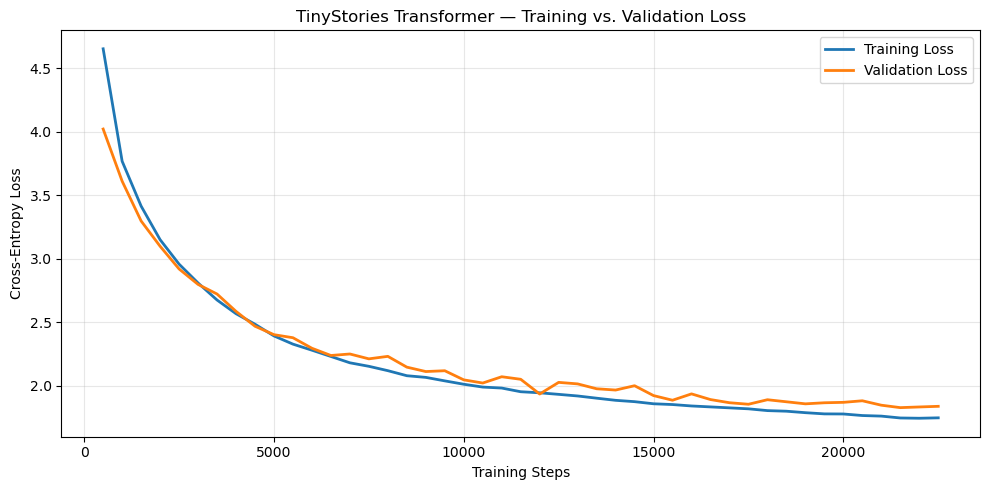

In [26]:
import matplotlib.pyplot as plt

steps = range(eval_interval, len(train_losses) * eval_interval + 1, eval_interval)

plt.figure(figsize=(10, 5))

plt.plot(steps, train_losses, label="Training Loss", linewidth=2)
plt.plot(steps, val_losses, label="Validation Loss", linewidth=2)

plt.xlabel("Training Steps")
plt.ylabel("Cross-Entropy Loss")
plt.title("TinyStories Transformer — Training vs. Validation Loss")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()